# Multimodal Classification: Accuracy, Prompt Sensitivity, and Abstention
**Joe Williams · Portfolio experiment 4 · Completed evaluation · 10,000 test images**

Can changing a model's text descriptions improve image classification? Can a fixed confidence cutoff route some errors for review without referring too many correct predictions?

This independent experiment builds on Chapter 9's CLIP concepts. A frozen CLIP model compares image embeddings with text embeddings for CIFAR-10's ten classes. No model weights are fitted. Three prompt configurations and all analysis choices are declared before evaluation.

**Run:** Upload this notebook to Google Colab, choose **Runtime → Change runtime type → T4 GPU**, then **Run all**. Use a fresh runtime. No API key is required. The final cell downloads a results ZIP; also download the executed notebook using **File → Download → Download .ipynb**. GPU availability and run time depend on Colab; the notebook does not assume a guaranteed session length.

This notebook is self-contained. The companion package contains the same helpers, tests, and an offline results verifier. The small preparation checks are reported separately from the completed benchmark results.

**Recorded result:** The development-selected photo prompt scored 88.23% overall. The primary fixed threshold accepted 75.18% of test images at 97.10% accuracy among accepted predictions, with 218 accepted errors and 2,482 referrals. Human-review corrections were not measured. All three prompt comparisons and the full interpretation appear below.


## 1. Install the tested libraries
The notebook keeps Colab's GPU-enabled PyTorch installation. PyTorch 2.6 or newer is needed to read this official checkpoint safely through Transformers. Encoder inference uses float32; scoring and metrics use float64.

In [1]:
import subprocess
import sys

# Install before importing these packages in a fresh runtime.
packages = ["transformers==4.57.6", "huggingface-hub==0.36.2", "numpy==2.3.5",
            "pandas==2.2.3", "pyarrow==23.0.1", "Pillow==13.0.0",
            "matplotlib==3.10.8", "tqdm>=4.66,<5"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])

0

## 2. Declare the experiment
| Choice | Fixed protocol |
|---|---|
| Prompt configurations | Label alone; one photo description; five-description ensemble |
| Prompt selection | 100 images per class from official training data; highest accuracy, simpler method wins ties |
| Threshold setting | A separate 100 images per class; target coverage 50%, 75%, and 90% |
| Primary operating point | 75% calibration coverage; test coverage is measured, not guaranteed |
| Final evaluation | All 10,000 official test images, with every method and threshold unchanged |
| Primary comparison metric | Top-1 accuracy; also macro F1, per-class recall, confusion counts |

Decoded RGB hashes exclude exact train/test copies from development sampling and remove repeated training images before splitting. The official test set stays intact. This is not a near-duplicate or model-pretraining audit. Labels retain the dataset's original order, including “automobile.”

The threshold uses the `ceil(target × N)`-th largest calibration score and accepts scores **greater than or equal to** it. Ties may exceed target coverage. “Calibration” here means choosing a cutoff; **we do not calibrate probability estimates**.

In [2]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import csv, hashlib, io, json, math, platform, shutil, time, uuid
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import display

CONFIG = json.loads('{\n  "experiment": "clip_prompt_abstention",\n  "seed": 2026,\n  "model_id": "openai/clip-vit-base-patch32",\n  "model_revision": "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268",\n  "dataset_id": "uoft-cs/cifar10",\n  "dataset_revision": "0b2714987fa478483af9968de7c934580d0bb9a2",\n  "class_names": [\n    "airplane",\n    "automobile",\n    "bird",\n    "cat",\n    "deer",\n    "dog",\n    "frog",\n    "horse",\n    "ship",\n    "truck"\n  ],\n  "method_order": [\n    "label_only",\n    "photo_prompt",\n    "prompt_ensemble"\n  ],\n  "templates": {\n    "label_only": [\n      "{label}"\n    ],\n    "photo_prompt": [\n      "a photo of {article} {label}."\n    ],\n    "prompt_ensemble": [\n      "a photo of {article} {label}.",\n      "a blurry photo of {article} {label}.",\n      "a close-up photo of {article} {label}.",\n      "a bright photo of {article} {label}.",\n      "a cropped photo of {article} {label}."\n    ]\n  },\n  "selection_per_class": 100,\n  "threshold_per_class": 100,\n  "coverage_targets": [\n    0.5,\n    0.75,\n    0.9\n  ],\n  "primary_coverage_target": 0.75,\n  "bootstrap_resamples": 2000,\n  "batch_size": 64,\n  "torch_threads": 4,\n  "precision": "float32",\n  "smoke_only": false,\n  "dataset_file_sha256": {\n    "train": "8428b53a88a11ac374111006708df51469e315a22ac6d66470afd9c78d2ae883",\n    "test": "841389e6f2d64f28bf17310e430aebac20ec3ba611a3c5e231dc93c645ce84de"\n  }\n}')
# A CLI preparation check can set SMOKE_ONLY; the Colab notebook uses False.
SMOKE_ONLY = bool(globals().get("SMOKE_ONLY", False))
CONFIG["smoke_only"] = SMOKE_ONLY
if SMOKE_ONLY:
    CONFIG["selection_per_class"] = 2
    CONFIG["threshold_per_class"] = 2
    CONFIG["test_source_split"] = "unused_training_rows_for_smoke_only"
else:
    CONFIG["test_source_split"] = "official_test"

np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
torch.set_num_threads(CONFIG["torch_threads"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
if not SMOKE_ONLY and DEVICE != "cuda":
    raise RuntimeError("Choose a Colab T4 GPU, then rerun from this cell.")
RUN_ID = ("smoke_" if SMOKE_ONLY else "multimodal_") + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
OUT = Path("artifacts") / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
print("Run:", RUN_ID, "| device:", DEVICE, "| smoke only:", SMOKE_ONLY)

Run: multimodal_20261124T171506Z-2512b9 | device: cuda | smoke only: False


## 3. Define the metrics
The helper functions below keep the denominators explicit. A confusion-matrix row is the actual class and a column is the predicted class. Macro F1 averages equally over the ten classes.

Selective accuracy is correct accepted predictions divided by **accepted predictions**, not all images. Referred errors have been routed for review; they have not been shown to be corrected by a person. A zero-sized accepted set has undefined accuracy (`None`).

The paired bootstrap resamples each image's correctness difference. Sampling the counts of −1, 0, and +1 differences is equivalent in distribution to sampling paired image rows, and uses much less memory.

In [3]:
"""Small, auditable NumPy metrics for a fixed multiclass experiment.

Class columns always follow the notebook's declared class order. Argmax ties
select the lowest class index. Softmax scores are not assumed to be calibrated
probabilities of correctness, even though each row sums to one.
"""

from collections.abc import Mapping
from math import ceil

import numpy as np


def _matrix(values, name):
    """Convert numeric input and reject malformed or non-finite matrices."""
    try:
        matrix = np.asarray(values, dtype=np.float64)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{name} must be a numeric matrix") from exc
    if matrix.ndim != 2 or not all(matrix.shape):
        raise ValueError(f"{name} must have nonempty shape (examples, classes)")
    if not np.isfinite(matrix).all():
        raise ValueError(f"{name} must contain only finite values")
    return matrix


def _probabilities(probabilities):
    probabilities = _matrix(probabilities, "probabilities")
    if np.any(probabilities < 0) or np.any(probabilities > 1):
        raise ValueError("probabilities must lie in [0, 1]")
    # A small tolerance accommodates float32 softmax output without silently
    # normalizing arbitrary scores into a different experiment.
    if not np.allclose(probabilities.sum(axis=1), 1.0, rtol=0, atol=1e-6):
        raise ValueError("each probability row must sum to one")
    return probabilities


def _labels(y_true, n_examples, n_classes):
    labels = np.asarray(y_true)
    if labels.ndim != 1 or len(labels) != n_examples:
        raise ValueError("y_true must have one label per example")
    if labels.dtype.kind not in "iu":
        raise ValueError("y_true must contain integer class indices")
    if np.any(labels < 0) or np.any(labels >= n_classes):
        raise ValueError("y_true contains an out-of-range class index")
    return labels.astype(np.int64, copy=False)


def _validated(y_true, probabilities):
    probabilities = _probabilities(probabilities)
    labels = _labels(y_true, *probabilities.shape)
    return labels, probabilities


def _unit_scalar(value, name, lower_inclusive=True):
    if isinstance(value, (bool, np.bool_)) or not np.isscalar(value):
        raise ValueError(f"{name} must be a finite number")
    try:
        value = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{name} must be a finite number") from exc
    lower_ok = value >= 0 if lower_inclusive else value > 0
    if not np.isfinite(value) or not lower_ok or value > 1:
        bounds = "[0, 1]" if lower_inclusive else "(0, 1]"
        raise ValueError(f"{name} must lie in {bounds}")
    return value


def softmax(logits):
    """Return stable float64 softmax scores for a nonempty N-by-K matrix."""
    logits = _matrix(logits, "logits")
    # Subtracting each row's maximum leaves softmax unchanged and avoids
    # overflow when logits are large. Extreme negative differences may become
    # -inf; their exponentials correctly become zero.
    with np.errstate(over="ignore", under="ignore"):
        exponentials = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exponentials / exponentials.sum(axis=1, keepdims=True)


def classification_metrics(y_true, probabilities):
    """Accuracy, fixed-class macro F1, and confusion counts.

Absent classes have recall None; macro F1 includes every declared probability
column, assigning zero F1 when both precision and recall denominators are zero.
The confusion matrix uses actual classes as rows and predictions as columns.
"""
    labels, probabilities = _validated(y_true, probabilities)
    predictions = probabilities.argmax(axis=1)
    n_examples, n_classes = probabilities.shape
    confusion = np.bincount(
        n_classes * labels + predictions, minlength=n_classes * n_classes
    ).reshape(n_classes, n_classes)
    correct = np.diag(confusion)
    actual_counts = confusion.sum(axis=1)
    predicted_counts = confusion.sum(axis=0)
    # F1 = 2 TP / (actual positives + predicted positives).
    f1_denominator = actual_counts + predicted_counts
    f1 = np.divide(
        2.0 * correct, f1_denominator,
        out=np.zeros(n_classes, dtype=np.float64), where=f1_denominator != 0,
    )
    recall = [
        float(correct[i] / actual_counts[i]) if actual_counts[i] else None
        for i in range(n_classes)
    ]
    return {
        "n_examples": int(n_examples),
        "accuracy": float(correct.sum() / n_examples),
        "macro_f1": float(f1.mean()),
        "per_class_recall": recall,
        "confusion_matrix": confusion.tolist(),
        "n_errors": int(n_examples - correct.sum()),
        "prediction_tie_break": "lowest_class_index",
    }


def choose_method(metrics_by_name, method_order):
    """Select highest development accuracy; ties use declared method order.

Only candidates in method_order are considered. The same order must be fixed
before evaluating development data, so tie handling is not selected afterward.
"""
    order = list(method_order)
    if not order or len(set(order)) != len(order):
        raise ValueError("method_order must be nonempty and contain no duplicates")
    if not isinstance(metrics_by_name, Mapping):
        raise ValueError("metrics_by_name must be a mapping")
    scores = []
    for name in order:
        if name not in metrics_by_name or "accuracy" not in metrics_by_name[name]:
            raise ValueError(f"missing accuracy for method {name!r}")
        scores.append(_unit_scalar(metrics_by_name[name]["accuracy"], "accuracy"))
    return order[int(np.argmax(scores))]


def coverage_threshold(confidence, target):
    """Choose a calibration-only cutoff reaching at least target coverage.

Take the ceil(target * N)-th largest score and retain scores >= the cutoff.
Ties can make observed calibration coverage exceed the requested target. This
does not guarantee the same coverage, or any accuracy, on a future/test set.
"""
    scores = np.asarray(confidence, dtype=np.float64)
    if scores.ndim != 1 or not len(scores) or not np.isfinite(scores).all():
        raise ValueError("confidence must be a nonempty finite vector")
    if np.any(scores < 0) or np.any(scores > 1):
        raise ValueError("confidence must lie in [0, 1]")
    target = _unit_scalar(target, "target", lower_inclusive=False)
    k = ceil(target * len(scores))
    return float(np.partition(scores, len(scores) - k)[len(scores) - k])


def selective_metrics(y_true, probs, threshold):
    """Measure retained and referred predictions at a fixed cutoff.

All class-specific quantities group by the true class. Referred errors are
errors routed for review, not errors proven resolved by a human. Accuracy is
undefined (None) if no examples are retained; error capture is undefined if
the original predictions contain no errors.
"""
    labels, probabilities = _validated(y_true, probs)
    threshold = _unit_scalar(threshold, "threshold")
    predictions = probabilities.argmax(axis=1)
    accepted = probabilities.max(axis=1) >= threshold
    errors = predictions != labels
    n_examples, n_classes = probabilities.shape
    accepted_count = int(accepted.sum())
    accepted_errors = int(np.sum(accepted & errors))
    referred_errors = int(np.sum(~accepted & errors))
    total_errors = int(errors.sum())
    per_class_coverage = []
    per_class_accuracy = []
    for class_id in range(n_classes):
        member = labels == class_id
        class_count = int(member.sum())
        retained_member = member & accepted
        retained_count = int(retained_member.sum())
        per_class_coverage.append(
            float(retained_count / class_count) if class_count else None
        )
        per_class_accuracy.append(
            float(np.sum(retained_member & ~errors) / retained_count)
            if retained_count else None
        )
    return {
        "threshold": threshold,
        "n_examples": int(n_examples),
        "accepted_count": accepted_count,
        "referred_count": int(n_examples - accepted_count),
        "coverage": float(accepted_count / n_examples),
        "selective_accuracy": (
            float(1 - accepted_errors / accepted_count) if accepted_count else None
        ),
        "selective_error_rate": (
            float(accepted_errors / accepted_count) if accepted_count else None
        ),
        "accepted_errors": accepted_errors,
        "referred_errors": referred_errors,
        "caught_error_fraction": (
            float(referred_errors / total_errors) if total_errors else None
        ),
        "correctly_accepted_fraction_total": float(
            (accepted_count - accepted_errors) / n_examples
        ),
        "per_class_coverage": per_class_coverage,
        "per_class_accepted_accuracy": per_class_accuracy,
    }


def paired_accuracy_bootstrap(y_true, probs_a, probs_b, resamples=2000, seed=2026):
    """Paired image-bootstrap descriptive interval for accuracy(B)-accuracy(A).

Each image contributes -1, 0, or +1 to the paired correctness difference.
Sampling the three category counts with a multinomial is exactly equivalent
in distribution to resampling N image indices with replacement. It preserves
pairing and avoids allocating a resamples-by-N index array. The interval is
conditional on these examples/models, not a domain-shift or causal guarantee.
"""
    labels, a = _validated(y_true, probs_a)
    b = _probabilities(probs_b)
    if a.shape != b.shape:
        raise ValueError("both methods must have matching example/class shapes")
    if isinstance(resamples, (bool, np.bool_)) or not isinstance(resamples, (int, np.integer)) or resamples < 1:
        raise ValueError("resamples must be a positive integer")
    if isinstance(seed, (bool, np.bool_)) or not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError("seed must be a nonnegative integer")
    a_correct = (a.argmax(axis=1) == labels).astype(np.int8)
    b_correct = (b.argmax(axis=1) == labels).astype(np.int8)
    differences = b_correct - a_correct
    counts = np.bincount(differences + 1, minlength=3)
    sampled_counts = np.random.default_rng(seed).multinomial(
        len(labels), counts / len(labels), size=resamples
    )
    sampled_deltas = (sampled_counts[:, 2] - sampled_counts[:, 0]) / len(labels)
    interval = np.quantile(sampled_deltas, [0.025, 0.975], method="linear")
    return {
        "mean_delta_b_minus_a": float(differences.mean()),
        "ci95": interval.tolist(),
        "b_better_count": int(counts[2]),
        "a_better_count": int(counts[0]),
        "tied_count": int(counts[1]),
        "resamples": int(resamples),
        "seed": int(seed),
        "resampling_unit": "paired_image",
    }

## 4. Load and audit the data
Pinned Parquet files are read directly. Each image is decoded to RGB before hashing. Only development sampling uses the duplicate exclusions; all official test images remain.

In [4]:
def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n', encoding='utf-8')


def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def decode_table(path):
    """Read pinned Parquet directly; do not execute a dataset loading script."""
    import pyarrow.parquet as pq
    from PIL import Image
    table = pq.read_table(path)
    labels = np.asarray(table['label'].to_pylist(), dtype=np.int64)
    column = 'img' if 'img' in table.column_names else 'image'
    images = []
    for item in table[column].to_pylist():
        with Image.open(io.BytesIO(item['bytes'])) as img:
            pixels = np.asarray(img.convert('RGB'), dtype=np.uint8)
            if pixels.shape != (32, 32, 3):
                raise ValueError('Unexpected CIFAR-10 image dimensions')
            images.append(pixels)
    return np.stack(images), labels


def load_data(config):
    """Download immutable source revisions and audit exact RGB duplicates."""
    from huggingface_hub import hf_hub_download
    import pyarrow.parquet as pq
    arrays, source = {}, {}
    for split, expected in [('train', 50000), ('test', 10000)]:
        relative = f'plain_text/{split}-00000-of-00001.parquet'
        path = hf_hub_download(config['dataset_id'], relative, repo_type='dataset',
                               revision=config['dataset_revision'])
        source_sha256 = file_hash(path)
        if source_sha256 != config['dataset_file_sha256'][split]:
            raise ValueError('Pinned dataset file hash differs')
        metadata = json.loads(pq.read_schema(path).metadata[b'huggingface'])
        if metadata['info']['features']['label']['names'] != config['class_names']:
            raise ValueError('Dataset class order differs from the protocol')
        images, labels = decode_table(path)
        if len(labels) != expected or not np.array_equal(np.bincount(labels, minlength=10),
                                                         np.full(10, expected // 10)):
            raise ValueError('Unexpected split size or class distribution')
        hashes = np.array([hashlib.sha256(x.tobytes()).hexdigest() for x in images])
        arrays[split] = {'images': images, 'labels': labels, 'hashes': hashes}
        source[split] = {'path_in_repository': relative, 'sha256': source_sha256,
                         'n_examples': len(labels)}
    train, test = arrays['train'], arrays['test']
    test_hashes = set(test['hashes'])
    seen = set()
    eligible = []
    cross_split_excluded = within_train_excluded = 0
    for i, h in enumerate(train['hashes']):
        if h in test_hashes:
            cross_split_excluded += 1
        elif h in seen:
            within_train_excluded += 1
        else:
            eligible.append(i)
            seen.add(h)
    audit = {
        'dataset_id': config['dataset_id'], 'revision': config['dataset_revision'],
        'source_files': source, 'hash_definition': 'SHA256 of decoded 32x32x3 RGB uint8 bytes',
        'train_rows_sharing_exact_pixels_with_test_excluded': cross_split_excluded,
        'additional_duplicate_train_rows_excluded': within_train_excluded,
        'eligible_training_rows': len(eligible),
        'duplicate_test_rows_beyond_first': len(test['hashes']) - len(test_hashes),
        'test_policy': 'Keep every official test row; report exact duplicates; no near-duplicate audit.',
        'pretraining_exposure': 'Unknown; zero-shot here means no task-specific weight fitting.'
    }
    return arrays, np.asarray(eligible, dtype=np.int64), audit


def sample_splits(labels, eligible, selection_per_class, threshold_per_class, seed):
    """Disjoint balanced samples; fixed RNG and original-row IDs are retained."""
    rng = np.random.default_rng(seed)
    dev, calibration = [], []
    n = selection_per_class + threshold_per_class
    for label in range(10):
        pool = eligible[labels[eligible] == label]
        if len(pool) < n:
            raise ValueError('Not enough eligible images in a class')
        selected = rng.choice(pool, size=n, replace=False)
        dev.extend(selected[:selection_per_class])
        calibration.extend(selected[selection_per_class:])
    return np.sort(dev).astype(np.int64), np.sort(calibration).astype(np.int64)

## 5. Define the image and text encoding steps
CLIP maps images and descriptions into the same vector space. Each text embedding is normalized; the ensemble averages within a class and normalizes again. Every image is encoded once and reused across methods. The checkpoint’s learned logit scale remains fixed. Softmax scores depend on the candidate classes and are not probabilities that a prediction is correct.

In [5]:
def load_clip(config, device):
    import torch
    from transformers import CLIPModel, CLIPTokenizerFast, CLIPImageProcessor
    torch.set_num_threads(config['torch_threads'])
    # Explicit eager attention and float32 reduce implementation ambiguity.
    model = CLIPModel.from_pretrained(config['model_id'], revision=config['model_revision'],
        use_safetensors=False, attn_implementation='eager').to(device).float().eval()
    model.requires_grad_(False)
    tokenizer = CLIPTokenizerFast.from_pretrained(config['model_id'], revision=config['model_revision'])
    processor = CLIPImageProcessor.from_pretrained(config['model_id'], revision=config['model_revision'])
    return model, tokenizer, processor


def build_text_prototypes(model, tokenizer, config, device):
    """Normalize each text vector, average by class, then normalize again."""
    import torch
    prompts, prototypes = {}, {}
    with torch.inference_mode():
        for method in config['method_order']:
            by_class, texts = [], []
            for label in config['class_names']:
                article = 'an' if label in ('airplane', 'automobile') else 'a'
                group = [t.format(label=label, article=article) for t in config['templates'][method]]
                texts.extend(group)
                by_class.append(group)
            inputs = tokenizer(texts, padding=True, truncation=False, return_tensors='pt').to(device)
            if inputs['input_ids'].shape[1] > model.config.text_config.max_position_embeddings:
                raise ValueError('A prompt exceeds the model token limit')
            features = model.get_text_features(**inputs).float()
            features = features / features.norm(dim=-1, keepdim=True)
            features = features.reshape(10, len(config['templates'][method]), -1).mean(dim=1)
            features = features / features.norm(dim=-1, keepdim=True)
            prototypes[method] = features.cpu().numpy()
            prompts[method] = by_class
    return prototypes, prompts


def encode_images(model, processor, images, config, device, description='Images'):
    """One encoder pass per image; every prompt method reuses the same vector."""
    import torch
    from PIL import Image
    from tqdm.auto import tqdm
    vectors = []
    if device == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()
    with torch.inference_mode():
        for start in tqdm(range(0, len(images), config['batch_size']), desc=description):
            batch = [Image.fromarray(x) for x in images[start:start+config['batch_size']]]
            inputs = processor(images=batch, return_tensors='pt').to(device)
            features = model.get_image_features(**inputs).float()
            features = features / features.norm(dim=-1, keepdim=True)
            vectors.append(features.cpu().numpy())
    if device == 'cuda':
        torch.cuda.synchronize()
    return np.concatenate(vectors), time.perf_counter() - started


def compute_logits(image_vectors, prototypes, logit_scale, method_order):
    # Shape: method x image x class. Use float64 scoring for stable saved metrics.
    return np.stack([logit_scale * image_vectors.astype(np.float64) @ prototypes[m].astype(np.float64).T
                     for m in method_order])


def summarize_split(y_true, logits, methods):
    return {m: classification_metrics(y_true, softmax(logits[i])) for i, m in enumerate(methods)}


def lock_protocol(config, dev_labels, dev_logits, threshold_logits):
    """No test data is accepted by this function."""
    metrics = summarize_split(dev_labels, dev_logits, config['method_order'])
    selected = choose_method(metrics, config['method_order'])
    idx = config['method_order'].index(selected)
    confidence = softmax(threshold_logits[idx]).max(axis=1)
    thresholds = {str(t): coverage_threshold(confidence, t) for t in config['coverage_targets']}
    return {'selected_method': selected, 'selection_metric': 'development top-1 accuracy',
            'tie_priority': config['method_order'], 'thresholds': thresholds,
            'threshold_rule': 'kth-largest calibration score, k=ceil(target*n); accept score>=threshold',
            'primary_coverage_target': config['primary_coverage_target'],
            'scores_are_calibrated_probabilities': False,
            'locked_before_test_inference': True}

## 6. Define the export and analysis steps
These helpers preserve numeric evidence, including scores for every image and method. The offline verifier can recompute metrics and check hashes. It cannot independently establish that model inference or source annotations were correct.

In [6]:
def evaluate_records(records, config, protocol):
    methods = config['method_order']
    metrics = {split: summarize_split(records[f'{split}_labels'], records[f'{split}_logits'], methods)
               for split in ('development', 'threshold', 'test')}
    index = methods.index(protocol['selected_method'])
    test_prob = softmax(records['test_logits'][index])
    selective = {target: selective_metrics(records['test_labels'], test_prob, threshold)
                 for target, threshold in protocol['thresholds'].items()}
    comparisons = {}
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        comparisons[f'{methods[b]}_minus_{methods[a]}'] = paired_accuracy_bootstrap(
            records['test_labels'], softmax(records['test_logits'][a]), softmax(records['test_logits'][b]),
            resamples=config['bootstrap_resamples'], seed=config['seed'])
    return metrics, selective, comparisons


def environment_record(device):
    import importlib.metadata as meta
    import torch
    names = ['torch','transformers','huggingface-hub','numpy','pandas','pyarrow','Pillow','matplotlib']
    return {'python': platform.python_version(), 'platform': platform.platform(), 'device': device,
            'gpu': torch.cuda.get_device_name(0) if device == 'cuda' else None,
            'versions': {name: meta.version(name) for name in names},
            'torch_threads': torch.get_num_threads(), 'precision': 'float32 encoder, float64 score/metric arithmetic'}


def export_results(out, config, records, protocol, audit, prompts, prototypes, timings, device):
    import pandas as pd
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    metrics, selective, comparisons = evaluate_records(records, config, protocol)
    for name, value in [('config', config), ('protocol', protocol), ('data_audit', audit), ('prompts', prompts),
                        ('metrics', metrics), ('selective_metrics', selective), ('paired_comparisons', comparisons),
                        ('timing', timings), ('environment', environment_record(device))]:
        write_json(out / f'{name}.json', value)
    np.savez_compressed(out / 'records.npz', **records)
    np.savez_compressed(out / 'text_prototypes.npz', **prototypes)
    rows, summary = [], []
    for split in ('development', 'threshold', 'test'):
        labels, ids = records[f'{split}_labels'], records[f'{split}_ids']
        for index, method in enumerate(config['method_order']):
            prob = softmax(records[f'{split}_logits'][index])
            pred = prob.argmax(axis=1)
            for k in range(len(labels)):
                rows.append({'split':split, 'row_id':int(ids[k]), 'method':method,
                             'actual_label':int(labels[k]), 'predicted_label':int(pred[k]),
                             'max_softmax_score':float(prob[k].max()), 'correct':bool(pred[k] == labels[k])})
            value = metrics[split][method]
            summary.append({'split':split, 'method':method, 'n_examples':value['n_examples'],
                            'accuracy':value['accuracy'], 'macro_f1':value['macro_f1']})
    predictions = pd.DataFrame(rows)
    predictions.to_csv(out / 'predictions.csv', index=False)
    pd.DataFrame(summary).to_csv(out / 'metrics_summary.csv', index=False)
    pd.DataFrame([{'calibration_target_coverage':float(k), **{x:y for x,y in v.items() if not isinstance(y,list)}}
                  for k,v in selective.items()]).to_csv(out / 'selective_summary.csv', index=False)
    errors = predictions[(predictions['split']=='development') &
                         (predictions['method']==protocol['selected_method']) & (~predictions['correct'])]
    errors = errors.sort_values(['max_softmax_score','row_id'], ascending=[False,True]).head(10).copy()
    errors['my_observation'] = ''
    errors.to_csv(out / 'error_analysis.csv', index=False)
    write_json(out / 'run_status.json', {'status':'complete', 'smoke_only':config['smoke_only'],
        'test_evaluated':len(records['test_labels']), 'human_review_outcomes_measured':False})
    return metrics, selective, comparisons, predictions


def plot_results(out, config, metrics, selective, protocol):
    import matplotlib.pyplot as plt
    out = Path(out)
    methods = config['method_order']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].bar(['Labels','Photo prompt','Ensemble'], [metrics['test'][m]['accuracy'] for m in methods], color=['#516880','#207e90','#c27c32'])
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel('Test accuracy')
    axes[0].set_title('Fixed prompt comparison')
    points = sorted(selective.values(), key=lambda x:x['coverage'])
    axes[1].plot([p['coverage'] for p in points], [p['selective_accuracy'] for p in points], 'o-', color='#207e90')
    axes[1].scatter([1], [metrics['test'][protocol['selected_method']]['accuracy']], marker='s', color='#516880', label='All predictions')
    axes[1].set(xlim=(0,1.03), ylim=(0,1.03), xlabel='Fraction of test images accepted', ylabel='Accuracy among accepted images', title='Thresholds fixed on separate calibration images')
    axes[1].legend()
    fig.suptitle('CLIP prompt sensitivity and abstention — recorded run')
    fig.tight_layout()
    fig.savefig(out/'accuracy_coverage.png', dpi=170)
    plt.show()
    plt.close(fig)


def finalize_manifest(out):
    out = Path(out)
    files = {str(p.relative_to(out)):file_hash(p) for p in sorted(out.rglob('*'))
             if p.is_file() and p.name != 'manifest_sha256.json'}
    write_json(out/'manifest_sha256.json', files)

## 7. Download sources and select disjoint development samples
Row IDs are local to a split: training row 12 and test row 12 are different images. Pixel hashes, rather than numeric IDs across splits, check exact overlap.

In [7]:
started = time.perf_counter()
DATA, ELIGIBLE, AUDIT = load_data(CONFIG)
TIMINGS = {"data_download_decode_audit_seconds": time.perf_counter() - started}
train = DATA["train"]
if SMOKE_ONLY:
    # Use only training images during preparation; do not expose official test predictions.
    dev_ids, other_ids = sample_splits(train["labels"], ELIGIBLE, 2, 4, CONFIG["seed"])
    cal_ids, test_ids = [], []
    for label in range(10):
        candidates = other_ids[train["labels"][other_ids] == label]
        cal_ids.extend(candidates[:2])
        test_ids.extend(candidates[2:])
    cal_ids, test_ids = np.sort(cal_ids), np.sort(test_ids)
    TEST_SOURCE = train
else:
    dev_ids, cal_ids = sample_splits(train["labels"], ELIGIBLE,
        CONFIG["selection_per_class"], CONFIG["threshold_per_class"], CONFIG["seed"])
    test_ids = np.arange(len(DATA["test"]["labels"]))
    TEST_SOURCE = DATA["test"]

assert not set(dev_ids) & set(cal_ids)
RECORDS = {}
for split, source, ids in [("development", train, dev_ids), ("threshold", train, cal_ids),
                           ("test", TEST_SOURCE, test_ids)]:
    RECORDS[f"{split}_ids"] = np.asarray(ids, dtype=np.int64)
    RECORDS[f"{split}_labels"] = source["labels"][ids]
    RECORDS[f"{split}_pixel_hashes"] = source["hashes"][ids]
write_json(OUT/"config.json", CONFIG)
write_json(OUT/"data_audit.json", AUDIT)
print(json.dumps(AUDIT, indent=2))
print({s:len(RECORDS[f"{s}_ids"]) for s in ("development","threshold","test")})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{
  "dataset_id": "uoft-cs/cifar10",
  "revision": "0b2714987fa478483af9968de7c934580d0bb9a2",
  "source_files": {
    "train": {
      "path_in_repository": "plain_text/train-00000-of-00001.parquet",
      "sha256": "8428b53a88a11ac374111006708df51469e315a22ac6d66470afd9c78d2ae883",
      "n_examples": 50000
    },
    "test": {
      "path_in_repository": "plain_text/test-00000-of-00001.parquet",
      "sha256": "841389e6f2d64f28bf17310e430aebac20ec3ba611a3c5e231dc93c645ce84de",
      "n_examples": 10000
    }
  },
  "hash_definition": "SHA256 of decoded 32x32x3 RGB uint8 bytes",
  "train_rows_sharing_exact_pixels_with_test_excluded": 0,
  "additional_duplicate_train_rows_excluded": 0,
  "eligible_training_rows": 50000,
  "duplicate_test_rows_beyond_first": 0,
  "test_policy": "Keep every official test row; report exact duplicates; no near-duplicate audit.",
  "pretraining_exposure": "Unknown; zero-shot here means no task-specific weight fitting."
}
{'development': 1000, 'threshold':

## 8. Load the frozen model and encode the descriptions
The five ensemble templates are a small predetermined set for this experiment, not the original CLIP paper’s complete prompt ensemble. Model loading and text encoding are setup costs.

In [8]:
started = time.perf_counter()
MODEL, TOKENIZER, PROCESSOR = load_clip(CONFIG, DEVICE)
TIMINGS["model_loading_seconds"] = time.perf_counter() - started
write_json(OUT/"preprocessing.json", PROCESSOR.to_dict())
started = time.perf_counter()
PROTOTYPES, PROMPTS = build_text_prototypes(MODEL, TOKENIZER, CONFIG, DEVICE)
TIMINGS["text_prototype_seconds"] = time.perf_counter() - started
LOGIT_SCALE = float(MODEL.logit_scale.exp().detach().cpu())
TIMINGS["fixed_logit_scale"] = LOGIT_SCALE
write_json(OUT/"prompts.json", PROMPTS)
for method in CONFIG["method_order"]:
    print(method, "— airplane prompts:", PROMPTS[method][0])
    assert np.allclose(np.linalg.norm(PROTOTYPES[method], axis=1), 1, atol=1e-5)

label_only — airplane prompts: ['airplane']
photo_prompt — airplane prompts: ['a photo of an airplane.']
prompt_ensemble — airplane prompts: ['a photo of an airplane.', 'a blurry photo of an airplane.', 'a close-up photo of an airplane.', 'a bright photo of an airplane.', 'a cropped photo of an airplane.']


## 9. Choose the prompt and lock review thresholds
Only development labels select the method. A separate sample supplies the thresholds. The protocol is saved before test-image inference begins. Reading test pixels for the fixed duplicate audit did not use test performance.

In [9]:
for split, ids in [("development", dev_ids), ("threshold", cal_ids)]:
    vectors, elapsed = encode_images(MODEL, PROCESSOR, train["images"][ids], CONFIG, DEVICE, split)
    TIMINGS[f"{split}_image_encoding_seconds"] = elapsed
    RECORDS[f"{split}_logits"] = compute_logits(vectors, PROTOTYPES, LOGIT_SCALE, CONFIG["method_order"])

PROTOCOL = lock_protocol(CONFIG, RECORDS["development_labels"],
    RECORDS["development_logits"], RECORDS["threshold_logits"])
write_json(OUT/"protocol.json", PROTOCOL)
LOCKED_PROTOCOL_SHA256 = file_hash(OUT/"protocol.json")
print(json.dumps(PROTOCOL, indent=2))
display(pd.DataFrame(summarize_split(RECORDS["development_labels"],
    RECORDS["development_logits"], CONFIG["method_order"])).T[["accuracy","macro_f1","n_errors"]])

selected_index = CONFIG["method_order"].index(PROTOCOL["selected_method"])
cal_scores = softmax(RECORDS["threshold_logits"][selected_index]).max(axis=1)
print("Calibration coverage, including threshold ties:")
print({target:float(np.mean(cal_scores >= cutoff)) for target,cutoff in PROTOCOL["thresholds"].items()})

{
  "selected_method": "photo_prompt",
  "selection_metric": "development top-1 accuracy",
  "tie_priority": [
    "label_only",
    "photo_prompt",
    "prompt_ensemble"
  ],
  "thresholds": {
    "0.5": 0.9353257567812249,
    "0.75": 0.7482685294311393,
    "0.9": 0.5136721436565947
  },
  "threshold_rule": "kth-largest calibration score, k=ceil(target*n); accept score>=threshold",
  "primary_coverage_target": 0.75,
  "scores_are_calibrated_probabilities": false,
  "locked_before_test_inference": true
}


,accuracy,macro_f1,n_errors
label_only,0.885,0.884665,115
photo_prompt,0.891,0.889754,109
prompt_ensemble,0.89,0.888999,110


Calibration coverage, including threshold ties:
{'0.5': 0.5, '0.75': 0.75, '0.9': 0.9}


## 10. Evaluate the fixed configurations on the test set
All three methods use the same test image vectors. These elapsed times describe batched work in this notebook; they are not request latency, production throughput, or independent runtime comparisons between prompt methods.

In [10]:
assert file_hash(OUT/"protocol.json") == LOCKED_PROTOCOL_SHA256
vectors, elapsed = encode_images(MODEL, PROCESSOR, TEST_SOURCE["images"][test_ids], CONFIG, DEVICE, "test" if not SMOKE_ONLY else "smoke training images")
TIMINGS["test_image_encoding_seconds"] = elapsed
started = time.perf_counter()
RECORDS["test_logits"] = compute_logits(vectors, PROTOTYPES, LOGIT_SCALE, CONFIG["method_order"])
TIMINGS["all_test_prompt_scoring_seconds"] = time.perf_counter() - started
TIMINGS["interpretation"] = "Setup and batched encoding/scoring; not per-request latency; download cache state varies."
assert file_hash(OUT/"protocol.json") == LOCKED_PROTOCOL_SHA256
METRICS, SELECTIVE, COMPARISONS, PREDICTIONS = export_results(OUT, CONFIG, RECORDS,
    PROTOCOL, AUDIT, PROMPTS, PROTOTYPES, TIMINGS, DEVICE)
assert file_hash(OUT/"protocol.json") == LOCKED_PROTOCOL_SHA256
display(pd.read_csv(OUT/"metrics_summary.csv").query("split == 'test'"))
display(pd.read_csv(OUT/"selective_summary.csv"))
print(json.dumps(COMPARISONS, indent=2))

,split,method,n_examples,accuracy,macro_f1
6,test,label_only,10000,0.8735,0.873388
7,test,photo_prompt,10000,0.8823,0.881679
8,test,prompt_ensemble,10000,0.8854,0.884662


,calibration_target_coverage,threshold,n_examples,accepted_count,referred_count,coverage,selective_accuracy,selective_error_rate,accepted_errors,referred_errors,caught_error_fraction,correctly_accepted_fraction_total
0,0.50,0.935326,10000,4912,5088,0.4912,0.992467,0.007533,37,1140,0.968564,0.4875
1,0.75,0.748269,10000,7518,2482,0.7518,0.971003,0.028997,218,959,0.814783,0.7300
2,0.90,0.513672,10000,8888,1112,0.8888,0.934068,0.065932,586,591,0.502124,0.8302


{
  "photo_prompt_minus_label_only": {
    "mean_delta_b_minus_a": 0.0088,
    "ci95": [
      0.0049,
      0.0131
    ],
    "b_better_count": 272,
    "a_better_count": 184,
    "tied_count": 9544,
    "resamples": 2000,
    "seed": 2026,
    "resampling_unit": "paired_image"
  },
  "prompt_ensemble_minus_label_only": {
    "mean_delta_b_minus_a": 0.0119,
    "ci95": [
      0.008,
      0.0162
    ],
    "b_better_count": 284,
    "a_better_count": 165,
    "tied_count": 9551,
    "resamples": 2000,
    "seed": 2026,
    "resampling_unit": "paired_image"
  },
  "prompt_ensemble_minus_photo_prompt": {
    "mean_delta_b_minus_a": 0.0031,
    "ci95": [
      0.0004975000000000001,
      0.0059
    ],
    "b_better_count": 116,
    "a_better_count": 85,
    "tied_count": 9799,
    "resamples": 2000,
    "seed": 2026,
    "resampling_unit": "paired_image"
  }
}


## 11. Visualize accuracy and review workload
For the selected photo prompt, the line connects only the three predeclared calibration thresholds; it is not a fully sampled risk–coverage curve. The primary operating point targets 75% calibration coverage. Test coverage can differ. Compare per-class coverage to see which true classes are referred more often.

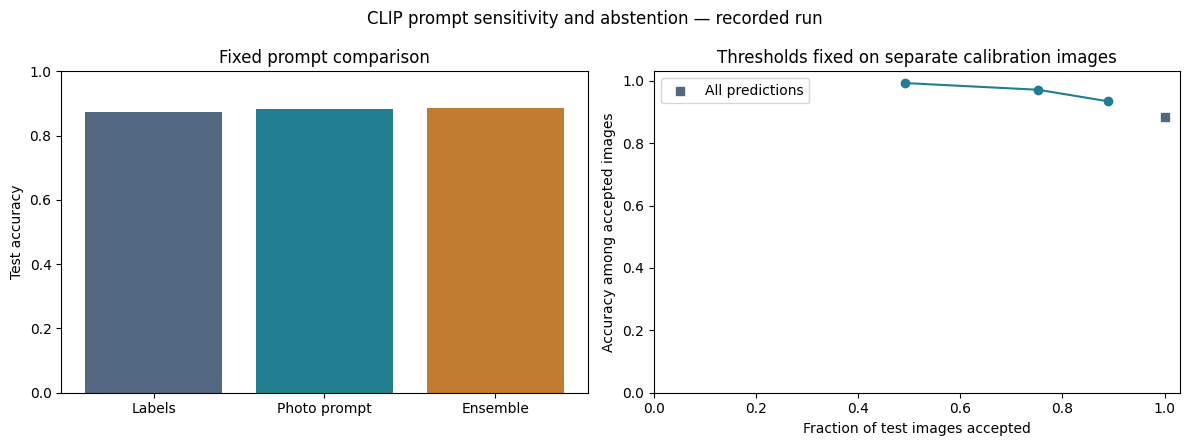

Selected method: photo_prompt
At the primary operating point: {
  "threshold": 0.7482685294311393,
  "n_examples": 10000,
  "accepted_count": 7518,
  "referred_count": 2482,
  "coverage": 0.7518,
  "selective_accuracy": 0.9710029263101889,
  "selective_error_rate": 0.02899707368981112,
  "accepted_errors": 218,
  "referred_errors": 959,
  "caught_error_fraction": 0.8147833474936279,
  "correctly_accepted_fraction_total": 0.73,
  "per_class_coverage": [
    0.784,
    0.829,
    0.769,
    0.687,
    0.663,
    0.768,
    0.435,
    0.918,
    0.886,
    0.779
  ],
  "per_class_accepted_accuracy": [
    0.9668367346938775,
    0.9806996381182147,
    0.9739921976592978,
    0.9679767103347889,
    0.8989441930618401,
    0.9622395833333334,
    0.9402298850574713,
    0.9978213507625272,
    0.9909706546275395,
    0.9974326059050064
  ]
}


,class,coverage,accepted_accuracy
0,airplane,0.784,0.966837
1,automobile,0.829,0.980700
2,bird,0.769,0.973992
3,cat,0.687,0.967977
4,deer,0.663,0.898944
5,dog,0.768,0.962240
6,frog,0.435,0.940230
7,horse,0.918,0.997821
8,ship,0.886,0.990971
9,truck,0.779,0.997433


Development errors for inspection:


,split,row_id,method,actual_label,predicted_label,max_softmax_score,correct,my_observation
0,development,35092,photo_prompt,4,7,0.938217,False,NaN
1,development,31566,photo_prompt,5,3,0.933507,False,NaN
2,development,46720,photo_prompt,4,7,0.929126,False,NaN
3,development,28279,photo_prompt,4,7,0.921014,False,NaN
4,development,7360,photo_prompt,5,3,0.909695,False,NaN
5,development,9311,photo_prompt,0,2,0.900033,False,NaN
6,development,39647,photo_prompt,5,4,0.883042,False,NaN
7,development,45583,photo_prompt,6,3,0.867181,False,NaN
8,development,35598,photo_prompt,4,7,0.854285,False,NaN
9,development,45661,photo_prompt,6,8,0.841806,False,NaN


In [11]:
plot_results(OUT, CONFIG, METRICS, SELECTIVE, PROTOCOL)
primary = SELECTIVE[str(CONFIG["primary_coverage_target"])]
print("Selected method:", PROTOCOL["selected_method"])
print("At the primary operating point:", json.dumps(primary, indent=2))
display(pd.DataFrame({"class":CONFIG["class_names"],
    "coverage":primary["per_class_coverage"],
    "accepted_accuracy":primary["per_class_accepted_accuracy"]}))
print("Development errors for inspection:")
display(pd.read_csv(OUT/"error_analysis.csv"))

## 12. Inspect one development image (optional)
Choose a row from the error table and set `SHOW_IMAGE = True`. Observations belong in the error worksheet; do not change benchmark labels. These are selected high-score errors, not a random sample of causes. Images are not bundled with the results ZIP.

In [12]:
SHOW_IMAGE = False
REVIEW_TRAIN_ROW_ID = 0
if SHOW_IMAGE:
    if REVIEW_TRAIN_ROW_ID not in set(dev_ids):
        raise ValueError("Choose a training row ID from this run's development table.")
    from PIL import Image
    display(Image.fromarray(train["images"][REVIEW_TRAIN_ROW_ID]).resize((256,256)))
    print("Actual class:", CONFIG["class_names"][train["labels"][REVIEW_TRAIN_ROW_ID]])
    display(PREDICTIONS[(PREDICTIONS["split"]=="development") &
                        (PREDICTIONS["row_id"]==REVIEW_TRAIN_ROW_ID)])

## 13. Interpret the evidence

### Prompt choice

Photo prompts scored 89.1% on development data, versus 88.5% for labels only and 89.0% for the ensemble. The fixed rule selected `photo_prompt`. On the 10,000-image test set, labels only scored 87.35%, the photo prompt scored 88.23%, and the ensemble scored 88.54%. The ensemble had the highest test accuracy, but the selected method and review thresholds remain unchanged.

The paired 95% bootstrap intervals for test accuracy differences were +0.49 to +1.31 percentage points for photo prompts versus labels, +0.80 to +1.62 for the ensemble versus labels, and +0.05 to +0.59 for the ensemble versus photo prompts. These are descriptive, unadjusted intervals from 2,000 resamples; they do not establish performance in a new business domain.

### Accuracy and review workload

| Threshold policy | Accepted / 10,000 | Accuracy among accepted | Accepted errors | Referred |
|---|---:|---:|---:|---:|
| 50% calibration target | 4,912 | 99.25% | 37 | 5,088 |
| **75% primary target** | **7,518** | **97.10%** | **218** | **2,482** |
| 90% calibration target | 8,888 | 93.41% | 586 | 1,112 |

At the primary cutoff, 7,300 images were correctly accepted. Of the 2,482 referred images, 959 had incorrect predictions and 1,523 had correct predictions. The policy routed 81.48% of the original 1,177 errors for review. It did not measure whether those errors were corrected. The 97.10% accuracy uses the accepted subset as its denominator; correctly accepted images were 73.00% of the full test set.

### Categories and error inspection

Frog images had a 56.5% referral rate, compared with 8.2% for horses. Accepted deer predictions were only 89.89% accurate despite the aggregate 97.10%. These retrospective groups use actual labels, which are unavailable for new unlabeled inputs. The ten displayed development errors are selected high-score mistakes, not a random sample of failure causes. The separately annotated worksheet records visual observations without changing benchmark labels.

### Business application and limits

The experiment models an image-tagging workflow: accept higher-scoring suggestions and queue the rest for review. A pilot should compare full review, full automation, and selective review on representative permitted images, measuring review time, reviewer errors, residual mistakes and cost per completed item. The benchmark alone does not establish business-domain performance, savings or production readiness.

CIFAR-10 contains small 32×32 images and ten fixed categories. Model pretraining overlap is unknown. The exact-pixel audit does not detect near duplicates. Maximum softmax is an uncalibrated score dependent on the candidate classes and scale. Bootstrap intervals do not account for domain shift, annotation uncertainty, correlated images or multiple comparisons. Test outcomes should not be used to retune this experiment and then reported as a fresh held-out result.

The offline check matched saved metrics and all 36,000 prediction rows. Independent metric checks and pinned-source alignment passed. No model inference was repeated during verification; execution chronology is not independently proved.


## 14. Save and download the evidence
The ZIP contains per-image scores, IDs and labels, text prompts, fixed choices, summary tables, duplicate counts, environment versions, the error worksheet, and file hashes. Downloads do not include images or model weights.

After the download, save the **executed notebook** too. The completed run is preserved in this repository under `results/`; verification and analysis are in `analysis/`. A rerun produces a separate evidence archive.

In [13]:
finalize_manifest(OUT)
ZIP_PATH = shutil.make_archive(str(OUT), "zip", root_dir=OUT.parent, base_dir=OUT.name)
print("Results:", OUT.resolve())
print("ZIP:", Path(ZIP_PATH).resolve())
if not SMOKE_ONLY:
    try:
        from google.colab import files
        files.download(ZIP_PATH)
    except ImportError:
        print("Outside Colab: download the ZIP from the notebook file browser.")

Results: /content/artifacts/multimodal_20261124T171506Z-2512b9
ZIP: /content/artifacts/multimodal_20261124T171506Z-2512b9.zip


## Sources
- Alammar, J., & Grootendorst, M. (2024). *Hands-On Large Language Models*, Chapter 9. [Official source notebook](https://github.com/HandsOnLLM/Hands-On-Large-Language-Models/tree/main/chapter09).
- Radford et al. (2021). [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020); [official CLIP repository](https://github.com/openai/CLIP).
- [CLIP checkpoint/model card](https://huggingface.co/openai/clip-vit-base-patch32), immutable revision recorded in `CONFIG`.
- Krizhevsky (2009). *Learning Multiple Layers of Features from Tiny Images*. [CIFAR-10 source](https://www.cs.toronto.edu/~kriz/cifar.html); [pinned-source dataset mirror](https://huggingface.co/datasets/uoft-cs/cifar10).
- [Transformers CLIP documentation](https://huggingface.co/docs/transformers/v4.57.2/model_doc/clip).

The experiment code is original for this portfolio, with conceptual attribution above. Dataset images and model weights are downloaded separately and retain their own terms; the code license does not relicense them.